# 10 · Part 1 - Customer classification (workspace)

Owner: ______  ·  Output: `outputs/part1_classification.csv` (one row per customer, a 0-1 score and a yes/no flag per technology)

The brief asks, for each technology: **which customers are likely to have it, with what confidence, and what evidence and method support that.** The sections below are empty on purpose. The cells provide data access, plots and the evaluation helper.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from avangrid.config import Paths, PROGRAM_BATTERY, INCREMENTAL_LOAD_LIMIT_KVA, SERVICE_KVA
from avangrid import pipeline, plots, labels, battery, features
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200)
P = Paths(ROOT)
D = pipeline.load_project(P)          # run 01_data_pipeline.ipynb once first
T = D.table
print(f"{len(T):,} customers | analysis-ready: {T.analysis_ready.sum():,}")

25,653 customers | analysis-ready: 25,170


## Tools
Look at any customers' day × hour heatmaps (rows = days Sep→Aug, columns = hours):

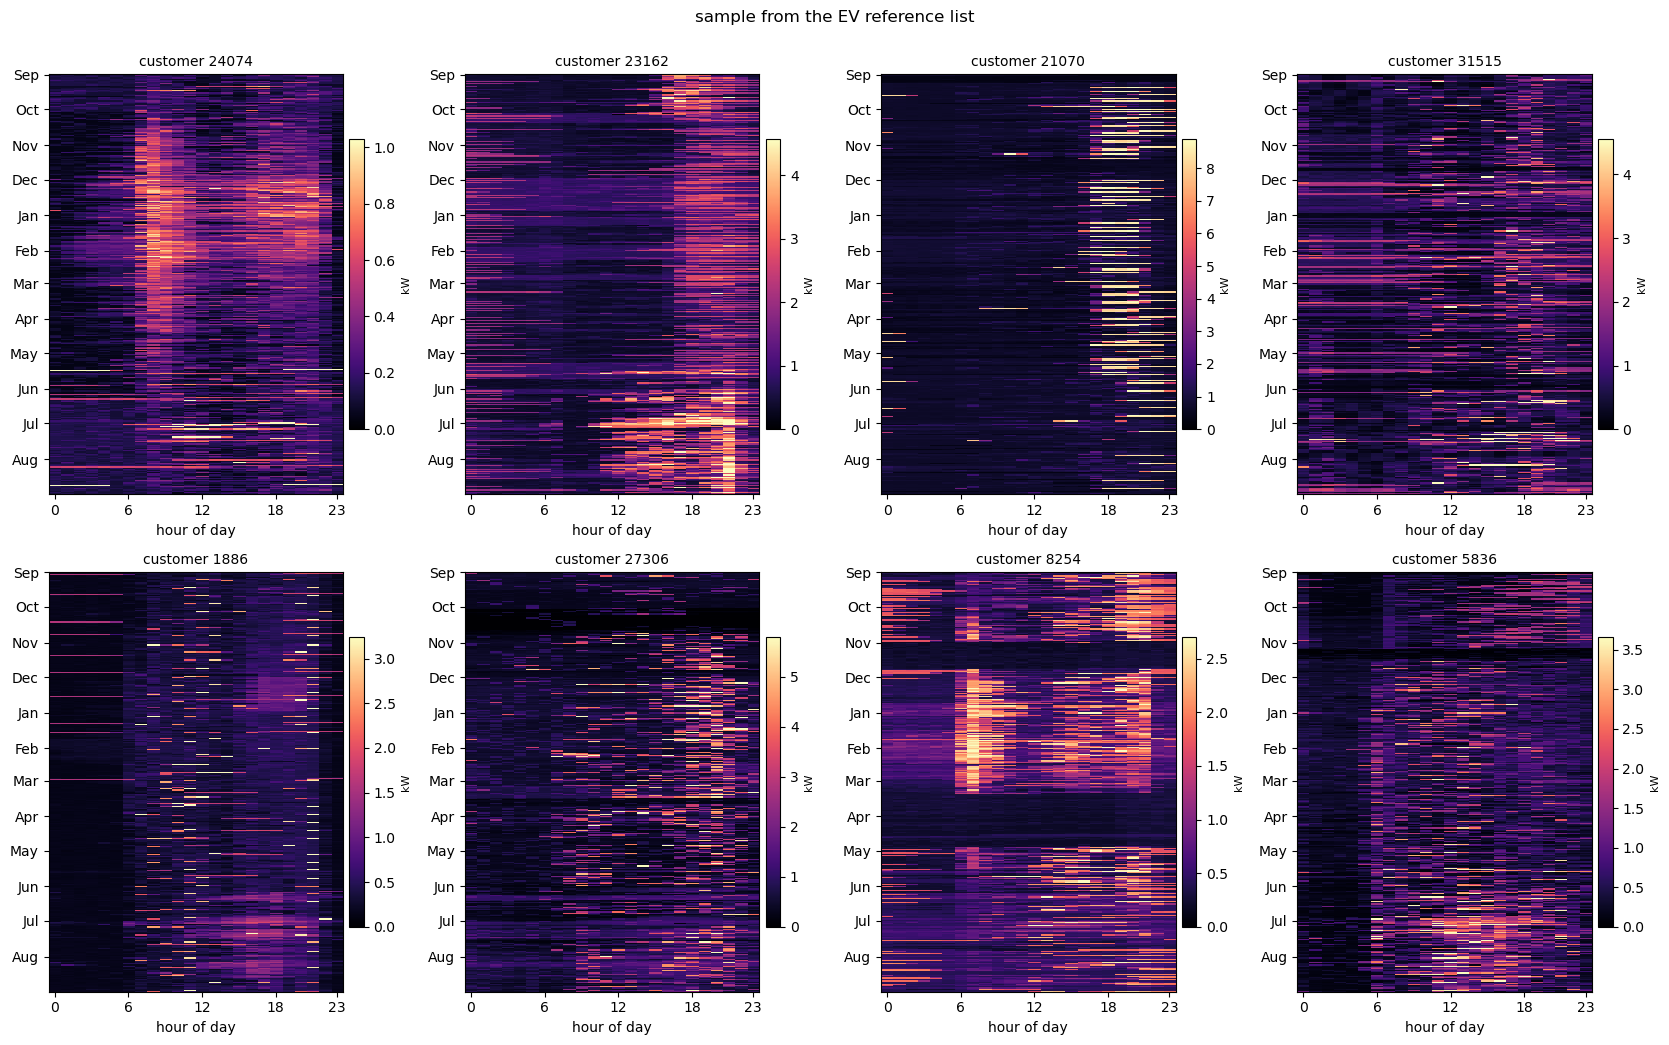

In [2]:
ids = T[T.ref_ev].customer_number.sample(8, random_state=1).tolist()
plots.heatmap_grid(D.kwh, D.customers, ids, suptitle="sample from the EV reference list"); plt.show()

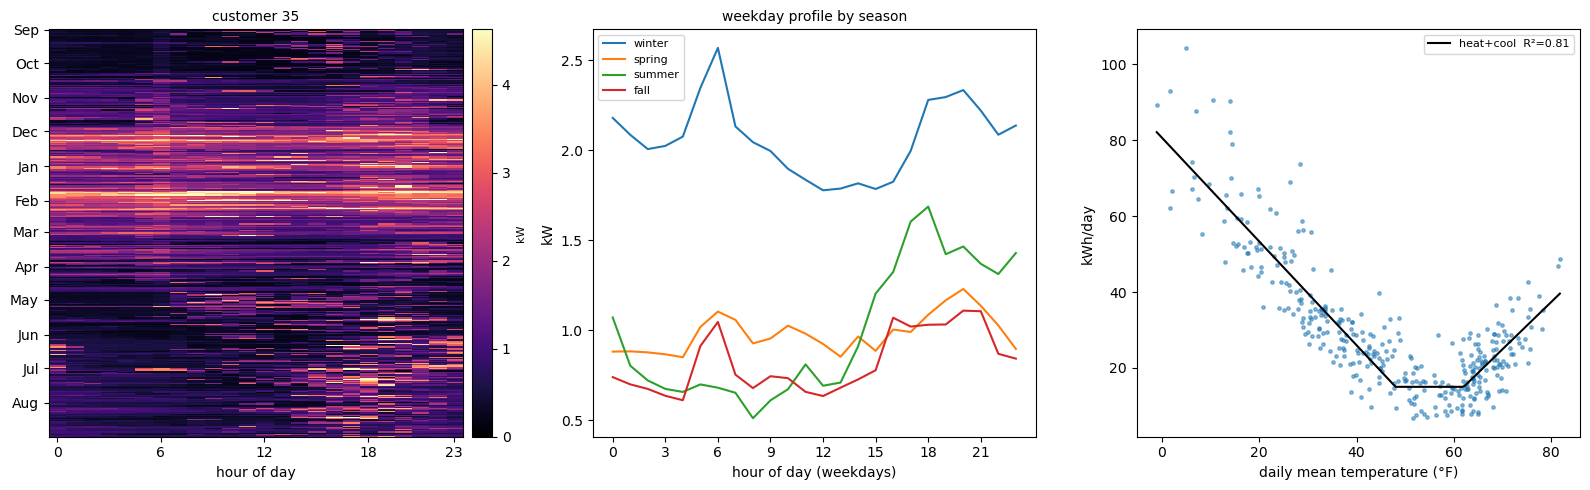

In [3]:
c = int(T[T.ref_hp].customer_number.iloc[0])
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
plots.heatmap(D.series(c), ax=axes[0], title=f"customer {c}")
plots.seasonal_profile(D.series(c), D.hours, ax=axes[1], title="weekday profile by season")
daily = D.series(c).reshape(365, 24).sum(1)
plots.temperature_scatter(daily, D.weather_daily.temp_mean.to_numpy(), fit=T.set_index("customer_number").loc[c], ax=axes[2])
plt.tight_layout(); plt.show()

Hold out part of each reference list **before** tuning, and only score against the holdout at the end:

In [4]:
splits = {k: labels.holdout_split(D.refs[k], frac=0.3, seed=42) for k in ("ev", "hp")}
# usage once you have a score Series indexed by customer_number:
# labels.pu_report(score, splits["ev"][1], label_fraction=0.25 * 0.3)

Other helpers: `features.runs_above(series, threshold_kw, min_hours)` lists every run of consecutive hours above a level for one customer. `D.feature_dictionary` defines every feature column.

## EV charging - Level 1
**Evidence / signature:** 

**Method:** 

**Validation:** 

## EV charging - Level 2
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Air conditioning
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Electric resistance heating
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Heat pumps (incl. mini-splits)
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Electric water heaters
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Swimming pools
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Hot tubs
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Solar + battery combinations
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Other segments / appliance signatures discovered
**Evidence / signature:** 

**Method:** 

**Validation:** 

## Export
One row per customer: `<tech>_score` (0-1) and `<tech>_flag` (bool) for each technology.

In [5]:
out = T[["customer_number"]].copy()
# out["ev_l2_score"] = ...; out["ev_l2_flag"] = out["ev_l2_score"] >= 0.7
# out.to_csv(P.outputs / "part1_classification.csv", index=False)